In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.feature_selection import RFE, RFECV
from sklearn.metrics import mean_squared_error, r2_score

# Настройки графиков
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', 20)

# 1. Загрузка и подготовка данных (Вариант 1)
df = sns.load_dataset('diamonds')
df = df.sample(n=300, random_state=1).dropna()

X = df[['carat', 'depth', 'table', 'x', 'y']]
y = df['price']
feature_names = X.columns.tolist()

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# 3. Стандартизация
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Объект кросс-валидации (для ЛР №6)
cv = KFold(n_splits=5, shuffle=True, random_state=1)

# 4. Подбор гиперпараметров (имитация ЛР №4, чтобы взять лучшие alpha)
# Используем небольшие сетки, чтобы код выполнился быстро
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 20), cv=cv).fit(X_train_s, y_train)
lasso_cv = LassoCV(alphas=np.logspace(-3, 3, 20), cv=cv, max_iter=10000).fit(X_train_s, y_train)
enet_cv = ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, .99, 1], alphas=np.logspace(-3, 3, 20), cv=cv, max_iter=10000).fit(X_train_s, y_train)

print(f"Лучшие параметры: Ridge alpha={ridge_cv.alpha_:.4f}, Lasso alpha={lasso_cv.alpha_:.4f}, ElasticNet alpha={enet_cv.alpha_:.4f}, l1_ratio={enet_cv.l1_ratio_:.2f}")

Лучшие параметры: Ridge alpha=1.4384, Lasso alpha=54.5559, ElasticNet alpha=54.5559, l1_ratio=1.00


In [ ]:
# Базовая модель на всех признаках
ols_all = LinearRegression().fit(X_train_s, y_train)
y_pred_all = ols_all.predict(X_test_s)

mse_all = mean_squared_error(y_test, y_pred_all)
r2_all = r2_score(y_test, y_pred_all)

print(f"Базовая модель OLS (все признаки):")
print(f"MSE = {mse_all:.2f}, R2 = {r2_all:.4f}")

Базовая модель OLS (все признаки):
MSE = 1681215.53, R2 = 0.8788


In [ ]:
n_select = max(1, X_train_s.shape[1] // 2) # Половина признаков (здесь 2)
estimator = LinearRegression()

rfe = RFE(estimator=estimator, n_features_to_select=n_select)
rfe.fit(X_train_s, y_train)

selected_rfe = np.array(feature_names)[rfe.support_]
print(f"RFE отобрал признаки (n={n_select}):", selected_rfe)
print("Ранги признаков:", dict(zip(feature_names, rfe.ranking_)))

RFE отобрал признаки (n=2): ['carat' 'x']
Ранги признаков: {'carat': np.int64(1), 'depth': np.int64(3), 'table': np.int64(4), 'x': np.int64(1), 'y': np.int64(2)}


Оптимальное число признаков: 4
RFECV отобрал признаки: ['carat' 'depth' 'x' 'y']


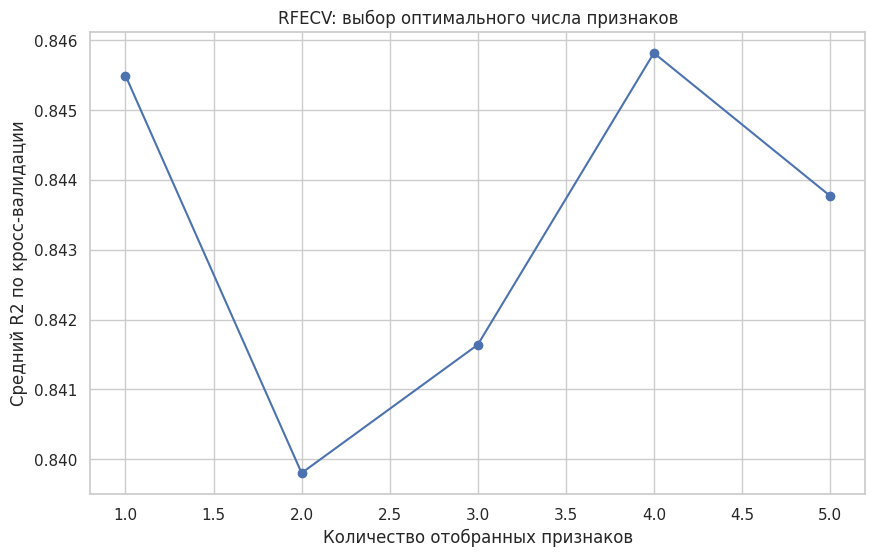

In [ ]:
rfecv = RFECV(estimator=estimator, step=1, cv=cv, scoring='r2', min_features_to_select=1)
rfecv.fit(X_train_s, y_train)

selected_rfecv = np.array(feature_names)[rfecv.support_]
print(f"Оптимальное число признаков: {rfecv.n_features_}")
print("RFECV отобрал признаки:", selected_rfecv)

# График зависимости R2 от числа признаков
plt.figure()
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1),
         rfecv.cv_results_['mean_test_score'], marker='o', color='b')
plt.xlabel('Количество отобранных признаков')
plt.ylabel('Средний R2 по кросс-валидации')
plt.title('RFECV: выбор оптимального числа признаков')
plt.grid(True)
plt.show()

In [ ]:
# Обучаем модель на отобранных RFECV признаках
X_train_rfecv = X_train_s[:, rfecv.support_]
X_test_rfecv = X_test_s[:, rfecv.support_]

ols_rfecv = LinearRegression().fit(X_train_rfecv, y_train)
y_pred_rfecv = ols_rfecv.predict(X_test_rfecv)

mse_rfecv = mean_squared_error(y_test, y_pred_rfecv)
r2_rfecv = r2_score(y_test, y_pred_rfecv)

print(f"Модель на RFECV-признаках:")
print(f"MSE = {mse_rfecv:.2f}, R2 = {r2_rfecv:.4f}")

print("\nСравнение:")
print(f"Все признаки:       MSE={mse_all:.2f}, R2={r2_all:.4f}")
print(f"RFECV-признаки ({len(selected_rfecv)}): MSE={mse_rfecv:.2f}, R2={r2_rfecv:.4f}")

Модель на RFECV-признаках:
MSE = 1660150.24, R2 = 0.8803

Сравнение:
Все признаки:       MSE=1681215.53, R2=0.8788
RFECV-признаки (4): MSE=1660150.24, R2=0.8803


In [ ]:
models = {
    'OLS (все признаки)': (LinearRegression(), X_train_s),
    'OLS (RFECV-отбор)': (LinearRegression(), X_train_s[:, rfecv.support_]),
    'Ridge': (Ridge(alpha=ridge_cv.alpha_), X_train_s),
    'Lasso': (Lasso(alpha=lasso_cv.alpha_, max_iter=10000), X_train_s),
    'ElasticNet': (ElasticNet(alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, max_iter=10000), X_train_s)
}

results = {}
for name, (model, Xd) in models.items():
    sc = cross_validate(model, Xd, y_train, cv=cv, scoring=('r2', 'neg_mean_squared_error'))
    results[name] = {
        'R2_cv_mean': sc['test_r2'].mean(),
        'RMSE_cv_mean': np.sqrt(-sc['test_neg_mean_squared_error']).mean()
    }

cv_df = pd.DataFrame(results).T
display(cv_df.round(4))

,R2_cv_mean,RMSE_cv_mean
OLS (все признаки),0.8438,1380.0257
OLS (RFECV-отбор),0.8458,1373.2918
Ridge,0.8471,1359.9457
Lasso,0.8478,1347.2303
ElasticNet,0.8478,1347.2303


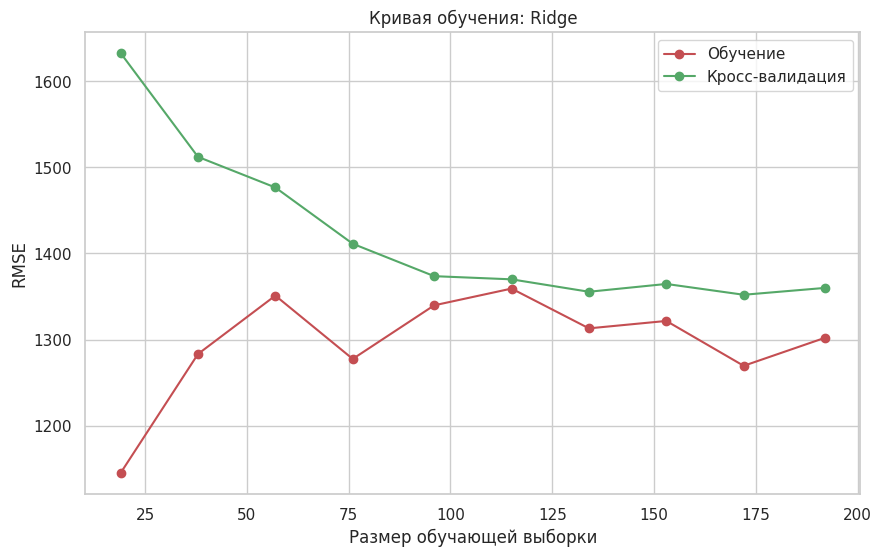

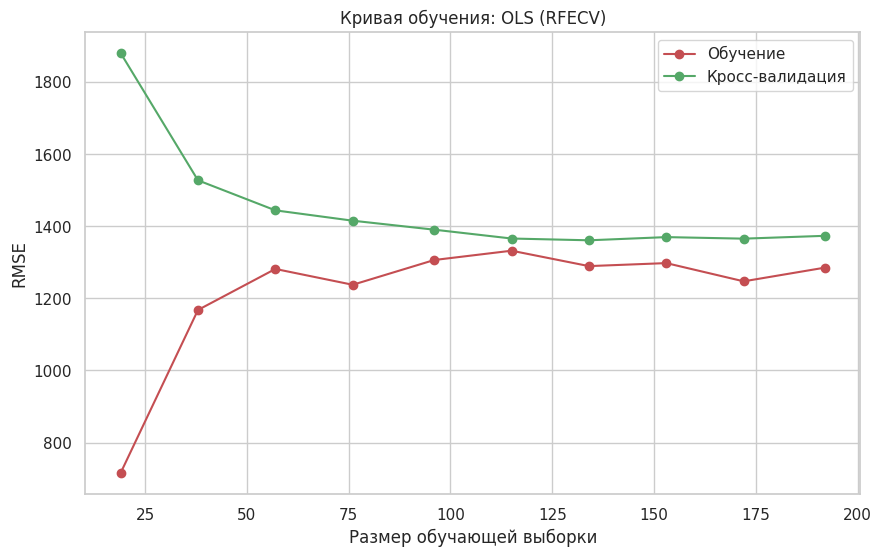

In [ ]:
def plot_learning_curve(estimator, X, y, title, cv):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=1
    )

    train_rmse = np.sqrt(-train_scores).mean(axis=1)
    val_rmse = np.sqrt(-val_scores).mean(axis=1)

    plt.plot(train_sizes, train_rmse, 'o-', color="r", label="Обучение")
    plt.plot(train_sizes, val_rmse, 'o-', color="g", label="Кросс-валидация")
    plt.xlabel("Размер обучающей выборки")
    plt.ylabel("RMSE")
    plt.title(title)
    plt.legend(loc="best")
    plt.grid(True)
    plt.show()

# Кривая для Ridge
plot_learning_curve(Ridge(alpha=ridge_cv.alpha_), X_train_s, y_train, "Кривая обучения: Ridge", cv)

# Кривая для OLS на RFECV
plot_learning_curve(LinearRegression(), X_train_s[:, rfecv.support_], y_train, "Кривая обучения: OLS (RFECV)", cv)

In [ ]:
# Обучаем итоговые модели на ПОЛНОЙ обучающей выборке
final_ridge = Ridge(alpha=ridge_cv.alpha_).fit(X_train_s, y_train)
final_ols_rfecv = LinearRegression().fit(X_train_s[:, rfecv.support_], y_train)

# Предсказания на тесте
y_pred_ridge = final_ridge.predict(X_test_s)
y_pred_ols_rfecv = final_ols_rfecv.predict(X_test_rfecv)

# Метрики
print("Оценка на тестовой выборке:")
print(f"Ridge:      MSE={mean_squared_error(y_test, y_pred_ridge):.2f}, R2={r2_score(y_test, y_pred_ridge):.4f}")
print(f"OLS RFECV:  MSE={mean_squared_error(y_test, y_pred_ols_rfecv):.2f}, R2={r2_score(y_test, y_pred_ols_rfecv):.4f}")

Оценка на тестовой выборке:
Ridge:      MSE=1777383.61, R2=0.8719
OLS RFECV:  MSE=1660150.24, R2=0.8803


In [ ]:
# Собираем все предсказания на тесте для сравнения
# (Для ЛР4 и ЛР5 мы берем только те, что смогли обучить в этом скрипте)
final_results = {
    'OLS (все)': {'MSE': mse_all, 'R2': r2_all},
    'OLS (RFECV)': {'MSE': mse_rfecv, 'R2': r2_rfecv},
    'Ridge': {'MSE': mean_squared_error(y_test, y_pred_ridge), 'R2': r2_score(y_test, y_pred_ridge)},
    # В реальной работе сюда добавятся Lasso, ElasticNet, QuantReg, Huber из ЛР4/5
    'Lasso': {'MSE': mean_squared_error(y_test, Lasso(alpha=lasso_cv.alpha_).fit(X_train_s, y_train).predict(X_test_s)),
              'R2': r2_score(y_test, Lasso(alpha=lasso_cv.alpha_).fit(X_train_s, y_train).predict(X_test_s))},
    'ElasticNet': {'MSE': mean_squared_error(y_test, ElasticNet(alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, max_iter=10000).fit(X_train_s, y_train).predict(X_test_s)),
                   'R2': r2_score(y_test, ElasticNet(alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, max_iter=10000).fit(X_train_s, y_train).predict(X_test_s))}
}

summary_df = pd.DataFrame(final_results).T
summary_df['RMSE'] = np.sqrt(summary_df['MSE'])
display(summary_df.round(4))

,MSE,R2,RMSE
OLS (все),1.681216e+06,0.8788,1296.6170
OLS (RFECV),1.660150e+06,0.8803,1288.4682
Ridge,1.777384e+06,0.8719,1333.1855
Lasso,1.971199e+06,0.8579,1403.9939
ElasticNet,1.971199e+06,0.8579,1403.9939
